# Training TerraMind-tiny on ImpactMesh-Flood

Trains on seg_train and picks the checkpoint on seg_val. The split keeps whole flood events
apart, so the model is never validated on an event it trained on. Each patch has two time steps,
before and during the flood. This second model adds optical images (Sentinel-2 L2A) to radar and elevation, to see
how much optical adds over the radar + elevation model. About half of the event-time optical
images are mostly cloud; they are used as they are.



## Machine

In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!df -h /content | tail -1

import os
print("CPU cores:", os.cpu_count())

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
overlay         242G   48G  195G  20% /
CPU cores: 12


## Settings

In [ ]:
DRIVE_ROOT = "/content/drive/MyDrive/flood_triage"
RUN_NAME = "terramind_tiny_s1s2dem_t2"
RUN_DIR = f"{DRIVE_ROOT}/runs/{RUN_NAME}"
LOCAL_SHARDS = "/content/shards"
MODALITIES = ['S2L2A', 'S1RTC', 'DEM']

BATCH_SIZES = [16, 8, 4, 2]   # tried in this order, the first one that fits is used
EFFECTIVE_BS = 16             # as in the ImpactMesh config; smaller batches use gradient accumulation
MAX_EPOCHS = 50
CKPT_EVERY_STEPS = 500
SEG_TRAIN_N = 15340           # patches in seg_train = one epoch

RUN_TRAINING = True   # False once the run is finished: the notebook then only shows the results

## Google Drive

In [4]:
from google.colab import drive
drive.mount("/content/drive")

for d in ["seg_train", "seg_val"]:
    folder = f"{DRIVE_ROOT}/shards/{d}"
    n = len([f for f in os.listdir(folder) if f.endswith(".tar")]) if os.path.isdir(folder) else 0
    print(d, n, "shards")
    assert n > 0, f"no shards in {folder}"

Mounted at /content/drive
seg_train 121 shards
seg_val 7 shards


## Install
Takes a few minutes. ImpactMesh is pinned to the commit used locally.

In [ ]:
%%capture install_log
!pip install terratorch==1.2.1 zarr==2.18.0 numcodecs==0.15.1 xarray==2025.10.1 torchgeo==0.9.0 webdataset==1.0.2
!test -d /content/ImpactMesh || git clone -q https://github.com/IBM/ImpactMesh.git /content/ImpactMesh
!git -C /content/ImpactMesh checkout -q 451038f21264256590eee0c73bec958897895213
!pip install -e /content/ImpactMesh --no-deps

In [6]:
import subprocess, sys

print(install_log.stdout[-1500:])

check = "import torch, importlib.metadata as m; import webdataset, impactmesh; print(torch.__version__, torch.cuda.is_available(), m.version('terratorch'))"
r = subprocess.run([sys.executable, "-c", check], capture_output=True, text=True)
print(r.stdout, r.stderr[-2000:])
# if CUDA shows False here, the install replaced torch: restart the session (VS Code: Restart button), then run all again

commit = subprocess.run(["git", "-C", "/content/ImpactMesh", "rev-parse", "HEAD"],
                        capture_output=True, text=True).stdout.strip()
assert commit.startswith("451038f"), commit

 all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.5.4 which is incompatible.
Obtaining file:///content/ImpactMesh
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for impactmesh (pyproject.toml) ... done
  Created wheel for impactmesh: filename=impactmesh-0.1.0-0.editable-py3-none-any.whl size=9705 sha256=deb03bd793d5bfc6e06a29b5580df6e34d55eeec205503fad3abea90a7fcd656
  Stored in directory: /tmp/pip-ephem-wheel-cache-s_l00c4g/wheels/43/34/3a/022cf2df7e6c0e90242ed535f8c29b707ace4c739594af85d5
Successfully built impactmesh

2.11.0+cu128 True 1.2.1
 


## Project code
Shard reader, profiling callback and config builder.

In [ ]:
!mkdir -p /content/code

In [8]:
%%writefile /content/code/triage_data.py
"""Reads the training shards.

Each sample holds s2l2a, s1rtc, dem and mask arrays (.npy, Blosc-compressed) and a meta.json.
Shapes: S2L2A (2, 12, 256, 256), S1RTC (2, 2, 256, 256), DEM (1, 256, 256), mask (256, 256);
time 0 is pre-event and time 1 is the event.
"""
import io
import json
import os
from functools import partial

import numpy as np
from numcodecs import Blosc

CODEC = Blosc(cname="zstd", clevel=5, shuffle=Blosc.SHUFFLE)
FILES = {"S2L2A": "s2l2a.npy.blosc", "S1RTC": "s1rtc.npy.blosc", "DEM": "dem.npy.blosc"}


def load_array(data):
    return np.load(io.BytesIO(CODEC.decode(data)))


def decode_sample(sample, modalities=("S2L2A", "S1RTC", "DEM")):
    """Raw shard sample -> the dict the ImpactMesh transforms expect. Only the given modalities
    are decompressed, which saves CPU time when training without S2."""
    out = {"__key__": sample["__key__"], "meta": json.loads(sample["meta.json"])}
    for mod in modalities:
        out[mod] = load_array(sample[FILES[mod]])
    out["mask"] = load_array(sample["mask.npy.blosc"]).astype(np.int64)
    return out


IMPORT_ERROR = None   # set if the datamodule could not be defined

try:  # the datamodule needs torch, terratorch and impactmesh
    if os.environ.get("TRIAGE_NO_TORCH") == "1":
        raise ImportError("TRIAGE_NO_TORCH is set")
    import webdataset as wds
    from torch.utils.data._utils.collate import default_collate
    from impactmesh.wds_impactmesh_datamodule import WdsImpactMeshDataModule
    from impactmesh.wds_impactmesh_dataset import make_transform

    class TriageWdsDataModule(WdsImpactMeshDataModule):
        """The ImpactMesh WebDataset datamodule, reading our shards. URLs can be one brace
        pattern or a list of them."""

        def _pipeline(self, urls, transform, shuffle):
            if isinstance(urls, (list, tuple)):
                urls = [u for pat in urls for u in wds.shardlists.expand_urls(pat)]
            steps = [
                wds.ResampledShards(urls) if shuffle else wds.SimpleShardList(urls),
                wds.split_by_node,
                wds.split_by_worker,
                wds.tarfile_to_samples(),
                wds.map(partial(decode_sample, modalities=tuple(self.modalities))),
            ]
            if shuffle:
                steps.append(wds.shuffle(self.shuffle_buffer))
            steps.append(wds.map(make_transform(
                self.modalities, self.timesteps, self.no_data_value,
                self.no_data_replace, transform, self.concat_bands)))
            steps.append(wds.batched(self.batch_size, collation_fn=default_collate, partial=not shuffle))
            return wds.DataPipeline(*steps)
except ImportError as e:
    IMPORT_ERROR = e

Writing /content/code/triage_data.py


In [9]:
%%writefile /content/code/profile_cb.py
"""Lightning callback: time per train/val batch (GPU step and incl. data loading) + peak GPU memory."""
import json
import os
import time

import torch
from lightning.pytorch.callbacks import Callback


def _sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


class ProfileCallback(Callback):
    def __init__(self, out_json: str, warmup: int = 5):
        self.out_json, self.warmup = out_json, warmup
        self.step, self.starts, self.val, self.t0 = [], [], [], None

    def on_train_start(self, trainer, pl_module):
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()

    def on_train_batch_start(self, trainer, pl_module, batch, batch_idx):
        _sync()
        self.t0 = time.perf_counter()
        self.starts.append(self.t0)

    def on_train_batch_end(self, trainer, pl_module, outputs, batch, batch_idx):
        _sync()
        self.step.append(time.perf_counter() - self.t0)

    def on_validation_batch_start(self, trainer, pl_module, batch, batch_idx, dataloader_idx=0):
        _sync()
        self.tv = time.perf_counter()

    def on_validation_batch_end(self, trainer, pl_module, outputs, batch, batch_idx, dataloader_idx=0):
        _sync()
        self.val.append(time.perf_counter() - self.tv)

    def on_fit_end(self, trainer, pl_module):
        med = lambda x: sorted(x)[len(x) // 2] if x else None
        mean = lambda x: sum(x) / len(x) if x else None
        step = self.step[self.warmup:] or self.step
        it = [b - a for a, b in zip(self.starts, self.starts[1:])][self.warmup:]
        val = self.val[2:] or self.val
        res = {"train_batches": len(self.step),
               "sec_per_batch_gpu_median": med(step),
               "sec_per_iter_incl_data_median": med(it), "sec_per_iter_incl_data_mean": mean(it),
               "val_batches": len(self.val), "sec_per_val_batch_mean": mean(val)}
        if torch.cuda.is_available():
            res["peak_allocated_GB"] = torch.cuda.max_memory_allocated() / 1e9
            res["peak_reserved_GB"] = torch.cuda.max_memory_reserved() / 1e9
            res["gpu"] = torch.cuda.get_device_name(0)
        os.makedirs(os.path.dirname(self.out_json), exist_ok=True)
        with open(self.out_json, "w") as f:
            json.dump(res, f, indent=1)

Writing /content/code/profile_cb.py


In [10]:
%%writefile /content/code/colab_cfg.py
"""TerraTorch configs for our runs, built from the ImpactMesh WebDataset config.

profile_config: a short run (50 train + 20 val batches) to measure memory and speed.
train_config: the full run on seg_train, validated on seg_val, saving to Drive.
"""
import glob
import os

import yaml

BASE = "/content/ImpactMesh/configs/terramind_v1_tiny_impactmesh_flood_wds.yaml"
N_T = 2  # the shards keep 2 of the 4 time steps
MODALITIES = ["S1RTC", "DEM"]  # radar + elevation; add "S2L2A" for the optical model


def _rel_pattern(root, name):
    n = len(glob.glob(os.path.join(root, name, "shard-*.tar")))
    if not n:
        raise FileNotFoundError(f"no shards in {os.path.join(root, name)}")
    return f"{name}/shard-" + ("{000000..%06d}" % (n - 1) if n > 1 else "000000")


def shard_pattern(root, *names):
    """Brace pattern for the shards in one or more folders, e.g. root/seg_val/shard-{000000..000011}.tar"""
    rel = [_rel_pattern(root, n) for n in names]
    p = os.path.join(root, rel[0] if len(rel) == 1 else "{" + ",".join(rel) + "}") + ".tar"
    p = p.replace("\\", "/")
    return ("file:" + p) if os.name == "nt" else p


def _common(base_path, shards, bs, workers, precision, seg_train_n, modalities):
    c = yaml.safe_load(open(base_path))
    d = c["data"]
    d["class_path"] = "triage_data.TriageWdsDataModule"
    a = d["init_args"]
    a.update(batch_size=bs, num_workers=workers, timesteps=list(range(N_T)), disaster="flood",
             modalities=list(modalities),
             train_epoch_size=seg_train_n,
             train_urls=shard_pattern(shards, "seg_train"),
             val_urls=shard_pattern(shards, "seg_val"),
             # fit never runs test; the holdout stays off Colab and is evaluated locally
             test_urls={"seg_val": shard_pattern(shards, "seg_val")})
    for t in a.get("train_transform", []):
        if t.get("class_path", "").endswith("UnflattenTemporalFromChannels"):
            t["init_args"]["n_timesteps"] = N_T
    m = c["model"]["init_args"]
    m["model_args"]["backbone_temporal_n_timestamps"] = N_T
    m["model_args"]["backbone_modalities"] = list(modalities)
    m["test_dataloaders_names"] = ["seg_val"]
    tr = c["trainer"]
    tr.update(precision=precision, devices=1)
    return c


def profile_config(out_dir, shards, bs, workers, precision, seg_train_n, base_path=BASE,
                   train_batches=50, val_batches=20, modalities=MODALITIES):
    c = _common(base_path, shards, bs, workers, precision, seg_train_n, modalities)
    tr = c["trainer"]
    tr.update(logger=False, enable_checkpointing=False, max_epochs=1, enable_progress_bar=False,
              limit_train_batches=train_batches, limit_val_batches=val_batches,
              num_sanity_val_steps=0, default_root_dir=os.path.join(out_dir, f"bs{bs}"))
    tr["callbacks"] = [{"class_path": "profile_cb.ProfileCallback",
                        "init_args": {"out_json": os.path.join(out_dir, f"bs{bs}.json")}}]
    c.pop("lr_scheduler", None)
    p = os.path.join(out_dir, f"profile_bs{bs}.yaml")
    os.makedirs(out_dir, exist_ok=True)
    yaml.safe_dump(c, open(p, "w"), sort_keys=False)
    return p


def train_config(run_dir, shards, bs, workers, precision, seg_train_n, base_path=BASE,
                 effective_bs=16, ckpt_every_steps=500, max_epochs=50, modalities=MODALITIES):
    """Same recipe as the ImpactMesh config: batch 16, lr 1e-4, dice loss, early stopping on
    val/loss with patience 10."""
    c = _common(base_path, shards, bs, workers, precision, seg_train_n, modalities)
    tr = c["trainer"]
    ckpt = os.path.join(run_dir, "checkpoints")
    tr.update(max_epochs=max_epochs, default_root_dir=run_dir,
              accumulate_grad_batches=max(1, effective_bs // bs), log_every_n_steps=20,
              logger={"class_path": "lightning.pytorch.loggers.CSVLogger",
                      "init_args": {"save_dir": run_dir, "name": "logs"}})
    tr["callbacks"] = [
        {"class_path": "LearningRateMonitor", "init_args": {"logging_interval": "epoch"}},
        {"class_path": "EarlyStopping", "init_args": {"monitor": "val/loss", "patience": 10}},
        # best model on val/loss
        {"class_path": "ModelCheckpoint",
         "init_args": {"dirpath": ckpt, "filename": "best_val_loss", "monitor": "val/loss",
                       "mode": "min", "save_top_k": 1, "save_weights_only": False}},
        # last.ckpt for resuming after a disconnect
        {"class_path": "ModelCheckpoint",
         "init_args": {"dirpath": ckpt, "filename": "step", "save_last": True, "save_top_k": 0,
                       "every_n_train_steps": ckpt_every_steps, "save_on_train_epoch_end": True,
                       "save_weights_only": False}},
    ]
    p = os.path.join(run_dir, "train_config.yaml")
    os.makedirs(run_dir, exist_ok=True)
    yaml.safe_dump(c, open(p, "w"), sort_keys=False)
    return p

Writing /content/code/colab_cfg.py


## Copy shards to the local disk
Reading straight from the Drive mount during training is too slow.

In [ ]:
import time

    t0 = time.time()
    for d in ["seg_train", "seg_val"]:
        !mkdir -p {LOCAL_SHARDS}/{d}
        !rsync -a --info=progress2 "{DRIVE_ROOT}/shards/{d}/" {LOCAL_SHARDS}/{d}/
    print(f"copied in {time.time() - t0:.0f} s")
    !du -sh {LOCAL_SHARDS}/*

 24,277,903,360 100%   11.51MB/s    0:33:31 (xfr#121, to-chk=0/122) 


  1,216,163,840 100%   11.98MB/s    0:01:36 (xfr#7, to-chk=0/8)


copied in 2111 s


23G	/content/shards/seg_train
1.2G	/content/shards/seg_val


## Precision and workers

In [12]:
import torch

sys.path.insert(0, "/content/code")
os.environ["PYTHONPATH"] = "/content/code:" + os.environ.get("PYTHONPATH", "")
import colab_cfg

# bf16 needs compute capability 8+ (A100, L4); the T4 is 7.5
cap = torch.cuda.get_device_capability(0)
PRECISION = "bf16-mixed" if cap[0] >= 8 else "16-mixed"
WORKERS = min(4, os.cpu_count() or 2)
print(torch.cuda.get_device_name(0), cap, PRECISION, "workers:", WORKERS)

NVIDIA L4 (8, 9) bf16-mixed workers: 4


## Profiling

About 50 training and 20 validation batches per batch size, to see what fits in memory and how long
a step takes. Results are saved to Drive, so this only runs once per GPU type.

In [13]:
import json, re

gpu = torch.cuda.get_device_name(0).replace(" ", "_")
prof_file = f"{RUN_DIR}/profile_{gpu}.json"

if os.path.exists(prof_file):
    results = json.load(open(prof_file))
    print("loaded", prof_file)
else:
    results = []
    for bs in BATCH_SIZES:
        cfg = colab_cfg.profile_config("/content/profile", LOCAL_SHARDS, bs, WORKERS, PRECISION, SEG_TRAIN_N,
                                       modalities=MODALITIES)
        r = subprocess.run(["terratorch", "fit", "--config", cfg], capture_output=True, text=True)
        log = r.stdout + r.stderr
        res = {"batch_size": bs, "returncode": r.returncode,
               "oom": bool(re.search(r"out of memory|OutOfMemoryError", log, re.I))}
        out = f"/content/profile/bs{bs}.json"
        if r.returncode == 0 and os.path.exists(out):
            res.update(json.load(open(out)))
        elif not res["oom"]:
            res["error_tail"] = log[-3000:]
        results.append(res)
        print(json.dumps(res, indent=1))
        if r.returncode == 0:
            break
    os.makedirs(RUN_DIR, exist_ok=True)
    json.dump(results, open(prof_file, "w"), indent=1)

fits = [r for r in results if r["returncode"] == 0 and not r["oom"]]
assert fits, "no batch size fitted, see error_tail above"
BS = max(r["batch_size"] for r in fits)
print("batch size", BS, "| gradient accumulation", max(1, EFFECTIVE_BS // BS))

{
 "batch_size": 16,
 "returncode": 0,
 "oom": false,
 "train_batches": 50,
 "sec_per_batch_gpu_median": 0.12049191899996003,
 "sec_per_iter_incl_data_median": 0.17349616799992873,
 "sec_per_iter_incl_data_mean": 0.2158498272727291,
 "val_batches": 20,
 "sec_per_val_batch_mean": 0.04680994677778472,
 "peak_allocated_GB": 3.015220736,
 "peak_reserved_GB": 3.221225472,
 "gpu": "NVIDIA L4"
}
batch size 16 | gradient accumulation 1


Batch size of 16 fits and uses around 3 GB of memory which is slighty more than the radar + DEM since this has 12 optical bands.

## Time estimate for the full run

In [ ]:
import math, glob, tarfile
    
    prof = next(r for r in results if r["batch_size"] == BS)
    n_val = sum(1 for f in glob.glob(f"{LOCAL_SHARDS}/seg_val/*.tar")
                for m in tarfile.open(f).getnames() if m.endswith("meta.json"))
    train_batches = math.ceil(SEG_TRAIN_N / BS)
    val_batches = math.ceil(n_val / BS)
    epoch_s = prof["sec_per_iter_incl_data_mean"] * train_batches + (prof["sec_per_val_batch_mean"] or 0) * val_batches
    
    print(f"peak GPU memory: {prof['peak_allocated_GB']:.2f} GB")
    print(f"step: {prof['sec_per_iter_incl_data_mean']:.3f} s with data loading, "
          f"{prof['sec_per_batch_gpu_median']:.3f} s on the GPU alone")
    print(f"one epoch: {epoch_s / 60:.1f} min ({train_batches} train + {val_batches} val batches)")
    print(f"{MAX_EPOCHS} epochs: {epoch_s * MAX_EPOCHS / 3600:.1f} h at most (early stopping may end it sooner)")
    
    json.dump({"batch_size": BS, "epoch_minutes": epoch_s / 60, "max_hours": epoch_s * MAX_EPOCHS / 3600},
              open(f"{RUN_DIR}/time_estimate.json", "w"), indent=1)

peak GPU memory: 3.02 GB
step: 0.216 s with data loading, 0.120 s on the GPU alone
one epoch: 3.5 min (959 train + 47 val batches)
50 epochs: 2.9 h at most (early stopping may end it sooner)


## Train

Checkpoints and logs go to `RUN_DIR` on Drive. If `checkpoints/last.ckpt` exists, training continues
from it. The shards are a shuffled stream, so a resumed epoch starts its data from scratch.
Only runs when `RUN_TRAINING` is True (see Settings).

In [15]:
if not RUN_TRAINING:
    print("training skipped: RUN_TRAINING is False. The results below come from the saved logs.")
else:
    settings = f"{RUN_DIR}/train_settings.json"
    if os.path.exists(settings):
        BS = json.load(open(settings))["batch_size"]   # keep the batch size of the run being resumed
    else:
        json.dump({"batch_size": BS, "precision": PRECISION}, open(settings, "w"))

    cfg = colab_cfg.train_config(RUN_DIR, LOCAL_SHARDS, BS, WORKERS, PRECISION, SEG_TRAIN_N,
                                 effective_bs=EFFECTIVE_BS, ckpt_every_steps=CKPT_EVERY_STEPS,
                                 max_epochs=MAX_EPOCHS, modalities=MODALITIES)
    last = f"{RUN_DIR}/checkpoints/last.ckpt"
    resume = f"--ckpt_path {last}" if os.path.exists(last) else ""
    print("resuming from " + last if resume else "starting a new run")

    os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"
    !terratorch fit --config {cfg} {resume}

starting a new run
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
/usr/local/lib/python3.12/dist-packages/lightning/pytorch/cli.py:734: `SemanticSegmentationTask.configure_optimizers` will be overridden by `MyLightningCLI.configure_optimizers`.
INFO: Using bfloat16 Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using bfloat16 Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cl

## Training results

Read from the logs on Drive, so this section works without training again. IoU is pooled over all
seg_val pixels; class 2 is flood, 1 permanent water, 0 no water. The checkpoint kept for later steps
is the epoch with the lowest validation loss.

best epoch 16 of 26


,val/loss,val/IoU_0,val/IoU_1,val/IoU_2,val/mIoU
epoch,,,,,
16.0,0.286,0.952,0.566,0.6,0.706


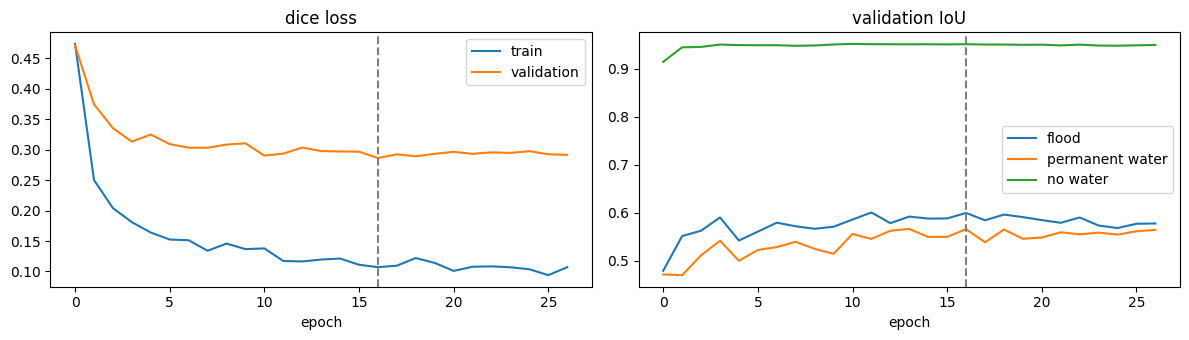

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

logs = sorted(glob.glob(f"{RUN_DIR}/logs/version_*/metrics.csv"))
df = pd.concat([pd.read_csv(f) for f in logs])
val = df.dropna(subset=["val/loss"]).drop_duplicates("epoch", keep="last").set_index("epoch")
train = df.dropna(subset=["train/loss"]).groupby("epoch")["train/loss"].mean()
best = val["val/loss"].idxmin()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(train.index, train, label="train")
ax[0].plot(val.index, val["val/loss"], label="validation")
ax[0].axvline(best, ls="--", c="gray")
ax[0].set_xlabel("epoch"); ax[0].set_title("dice loss"); ax[0].legend()
for col, label in [("val/IoU_2", "flood"), ("val/IoU_1", "permanent water"), ("val/IoU_0", "no water")]:
    ax[1].plot(val.index, val[col], label=label)
ax[1].axvline(best, ls="--", c="gray")
ax[1].set_xlabel("epoch"); ax[1].set_title("validation IoU"); ax[1].legend()
plt.tight_layout()

print(f"best epoch {best:.0f} of {val.index.max():.0f}")
val.loc[[best], ["val/loss", "val/IoU_0", "val/IoU_1", "val/IoU_2", "val/mIoU"]].round(3)

The best epoch appears to be epoch 16 and early stopping ended then run at 26 which is sooner than the radar + DEM run. seg_val IoU against radar+DEM: flood 0.600 vs 0.588, permanent water 0.566 vs 0.560, no water 0.952 vs 0.950. So adding optical helps only slightly here. A likely reason might be about half of flood-time optical images are cloudy (exploration section 6).
The same train/validation gap as before (training loss about 0.10, validation about 0.29).

In [17]:
!ls -la {RUN_DIR}/checkpoints

total 199049
-rw------- 1 root root 101912835 Oct 13 06:56 best_val_loss.ckpt
-rw------- 1 root root 101912835 Oct 13 07:26 last.ckpt
